# Notebook 2 · Optimización de objetivo único con PSO

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica
**UNAM · Instituto de Geología · Educación Continua y a Distancia · 10 de noviembre de 2026**
Dr. Abelardo Rodríguez Pretelín · Laboratorio HIDRA

En este notebook se muestra el uso de la herramienta **PSO** (enjambre de partículas) como optimizador para problemas de objetivo único: primero en
funciones de prueba cuyo óptimo conocemos, para aprender a usarla, y después en el acuífero de Fritz, primero en su versión lineal y después en una no lineal.

**Literatura:**

1. Clerc, M. (2010). *Particle Swarm Optimization* (Vol. 93). John Wiley & Sons.
2. Kennedy, J. y Eberhart, R. (1995). Particle swarm optimization. En *Proceedings of ICNN'95, International Conference on Neural Networks* (Vol. 4, pp. 1942–1948). IEEE.

---

### Cómo usar este cuaderno

- Ejecuta las celdas **en orden** con `Shift + Enter`. Algunas celdas tardan cerca de un minuto (lo dicen arriba): déjalas correr.
- Las cajas ✏️ **Tu turno** (cuatro, de dos minutos) dicen qué hacer, qué observar y una pregunta; la celda de abajo es tuya: cambia el número marcado con ← y vuelve a ejecutar. Al final de cada caja, plegado, está lo que debías ver.
- Las cajas ✔ **Punto de control · ⏸ Ejecuta hasta aquí** cierran las secciones 1, 2 y 3: dicen qué resultado debe verse. Ahí nos esperamos.
- Las figuras salen de funciones de `hidra` (`hidra.poblacion`, `hidra.convergencia`…): una línea dibuja; el código que se lee es el del algoritmo.
- El **Apéndice · en casa** guarda lo que no cabe en la sesión (tres ejemplos, dos animaciones y el barrido de precios). Corre después del cierre; no se ve en clase.

| Sección | Programa | Qué se hace |
|---|---|---|
| 1 | 2.3 · PSO introductorio | funciones de prueba: cómo se usa PSO, paso a paso y cuatro ejemplos de uso (16 min) |
| 2 | 2.4 · PSO hidrogeológico | el problema del original, **lineal**: PSO contra la verdad exacta de `linprog` (20 min) |
| 3 | 2.4 · PSO hidrogeológico | la ampliación **no lineal**: el beneficio neto, donde `linprog` ya no sirve (15 min) |
| 4 | puente | otra geología, otro óptimo (7 min) |
| A | en casa | ejemplos 4, 6 y 7, las dos animaciones y el precio |

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 0 · PREPARACIÓN</p>

## 0 · Preparación (2 min)

Además de `hidra` (el acuífero del curso, una carpeta arriba) usamos `pso.py`, que está en `Información/codigo` de esta sesión: un PSO completo en unas
100 líneas, sin nada escondido.

Importar dependencias:

In [1]:
import sys; sys.path.append('..'); sys.path.append('Información/codigo')   # hidra.py (arriba) y pso.py
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

import hidra                          # el acuífero del curso
import pso                            # el enjambre de partículas del curso

hidra.verificar_entorno()

Python 3.11.14 | numpy 2.4.1 | scipy 1.17.0 | matplotlib 3.10.8 | plotly 6.7.0 | otter 7.0.0


Simulador listo: una corrida tarda 0.74 s. Resultado(bombeos=[100.0, 100.0, 100.0] m³/d → abatimientos en pozos=[0.90, 0.92, 0.92] m, humedal=0.48 m)
ENTORNO LISTO


<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 1 · PSO CON FUNCIONES DE PRUEBA · PROGRAMA 2.3</p>

## 1 · PSO con funciones de prueba (16 min)

Antes de usar un optimizador en un acuífero conviene usarlo donde **conocemos la respuesta**.

### Función objetivo: Sphere

$$
f(\mathbf{x}) = \sum_{i=1}^{d} x_i^2
$$

**Descripción.** La función Sphere tiene un solo mínimo, el global: es continua, **convexa** y **unimodal** (un solo valle). Cualquier método que baje
la cuesta llega al fondo; sirve para comprobar que el optimizador funciona antes de darle algo difícil.

**Dominio.** Se evalúa normalmente en el hipercubo

$$
x_i \in [-5.12,\ 5.12], \quad \text{para todo} \quad i = 1, \ldots, d
$$

**Mínimo global.**

$$
f(\mathbf{x}^*) = 0, \quad \text{en} \quad \mathbf{x}^* = (0, \dots, 0)
$$

### 1.1 Definición de la función objetivo

In [2]:
# Función objetivo de muestra
def Sphere(x):
    return sum(x**2)

print(Sphere(np.array([0.0, 0.0])), Sphere(np.array([3.0, -4.0])))     # en el óptimo: 0 · en (3, -4): 9 + 16 = 25

0.0 25.0


### 1.2 Definir las condiciones del problema

In [3]:
# Definir el problema de optimización
problem = {
        'CostFunction': Sphere,
        'nVar': 2,
        'VarMin': -5,
        'VarMax': 5,
    }

### 1.3 Correr PSO

**Los parámetros del enjambre** son los de la lámina *Movimiento y posición*:

| Parámetro | Qué controla | Aquí |
|---|---|---|
| `PopSize` | cuántas partículas | 50 |
| `MaxIter` | cuántas iteraciones (pasos) | 200 |
| `w` | inercia: cuánto conserva cada partícula de su velocidad anterior | 1 |
| `wdamp` | amortiguamiento: en cada iteración, `w = w · wdamp` | 0.995 |
| `c1`, `c2` | atracción hacia su mejor posición propia (cognitiva) y hacia la mejor del enjambre (social) | 1.5 y 2 |
| `verbose` | `True` imprime el avance de cada iteración; `False` trabaja en silencio | `False` |

**Las ecuaciones.** Para cada partícula $i$, en cada iteración:

$$
\mathbf{v}_i \leftarrow \underbrace{w\,\mathbf{v}_i}_{\text{inercia}} + \underbrace{c_1\,\mathbf{r}_1 \odot (\mathbf{p}_i - \mathbf{x}_i)}_{\text{su propia experiencia}} + \underbrace{c_2\,\mathbf{r}_2 \odot (\mathbf{g} - \mathbf{x}_i)}_{\text{la experiencia del enjambre}}, \qquad
\mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i
$$

**donde** $\mathbf{p}_i$ es la mejor posición que ha visitado la partícula, $\mathbf{g}$ la mejor de todo el enjambre y $\mathbf{r}_1, \mathbf{r}_2$ números al azar
entre 0 y 1 (uno por variable): son los que hacen al PSO **estocástico**. Costo de la corrida: 50 × 200 = **10 000 evaluaciones** de la función objetivo.

In [4]:
# Correr PSO
np.random.seed(0)                      # fija el azar: así todos vemos el mismo resultado
pso.tic()
print('Running PSO ...')
gbest, pop = pso.PSO(problem, MaxIter = 200, PopSize = 50, c1 = 1.5, c2 = 2, w = 1, wdamp = 0.995, verbose = False)
print()
pso.toc()
print()

Running PSO ...

Elapsed time: 0.06 s



In [5]:
# Imprimir el resultado
print('Global Best:')
print(gbest)
print()

Global Best:
{'position': array([ 4.57387833e-15, -1.03155035e-14]), 'cost': np.float64(1.273299744429373e-28)}



<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 1 · ¿Con cuántas evaluaciones te conformas?</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: 10 partículas × 20 iteraciones = 200 evaluaciones, cincuenta veces menos que arriba.</li><li>Cambia los dos números de la primera línea (prueba 20 × 50 y 50 × 100) y vuelve a ejecutar.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · el mejor costo que imprime, frente al de arriba (50 × 200 = 10 000 evaluaciones: del orden de 10⁻²⁸).</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · si la meta fuera un costo menor que 0.001, ¿cuál es el presupuesto más chico que te sirve?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con 10 × 20 el mejor costo queda cerca de 2.7 × 10⁻³: todavía no. Con 20 × 50 baja a 6.4 × 10⁻⁵ y con 50 × 100 a 7.4 × 10⁻⁹. El presupuesto compra decimales; cuántos necesitas lo decide el problema, no el algoritmo: para Fritz bastan dos.</p></details>
</div>

In [6]:
PopSize_tt, MaxIter_tt = 10, 20          # ← cambia estos dos números
np.random.seed(0)
g_tt, _ = pso.PSO(problem, MaxIter=MaxIter_tt, PopSize=PopSize_tt, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
print(f"{PopSize_tt} partículas × {MaxIter_tt} iteraciones = {PopSize_tt * MaxIter_tt} evaluaciones -> mejor costo {g_tt['cost']:.2e} en {np.round(g_tt['position'], 3)}")

10 partículas × 20 iteraciones = 200 evaluaciones -> mejor costo 2.72e-03 en [-0.018  0.049]


### 1.4 Visualizar resultado

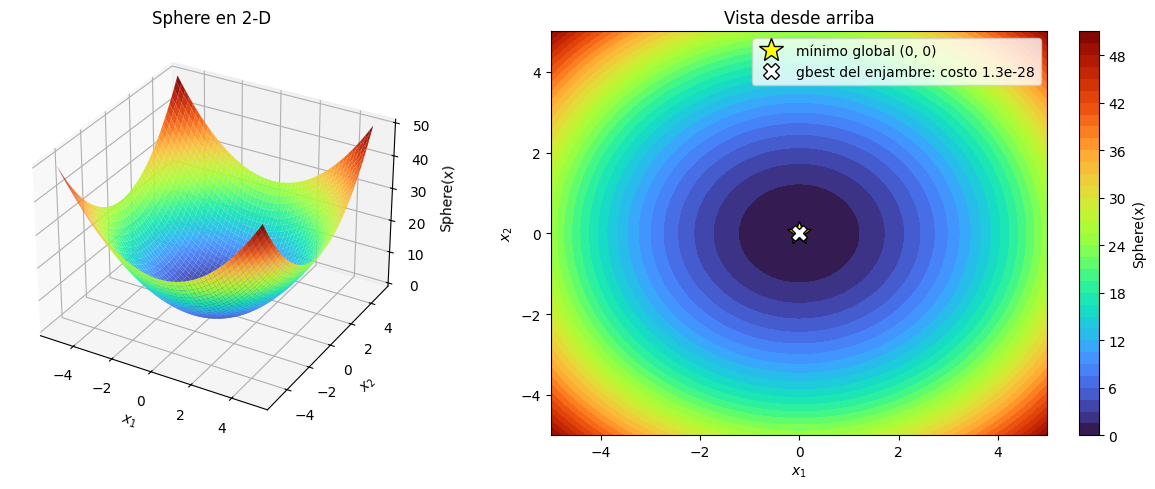

In [7]:
hidra.superficie_prueba(Sphere, lim=(problem['VarMin'], problem['VarMax']), gbest=gbest, nombre='Sphere')

### 1.5 Paso a paso en el algoritmo

`pso.PSO` no tiene magia. Aquí está el mismo algoritmo escrito a la vista, en los bloques del cuaderno original, para que reconozcas cada término
de la ecuación de velocidad.

**Bloque 1: parámetros.**

In [8]:
CostFunction = Sphere
nVar, VarMin, VarMax = 2, -5, 5
MaxIter, PopSize = 50, 20
w, wdamp, c1, c2 = 1.0, 0.95, 1.5, 2.0
np.random.seed(1)

👀 **Lo que acabamos de definir, en un dibujo:** el terreno de juego (el dominio de Sphere) y los parámetros del enjambre.

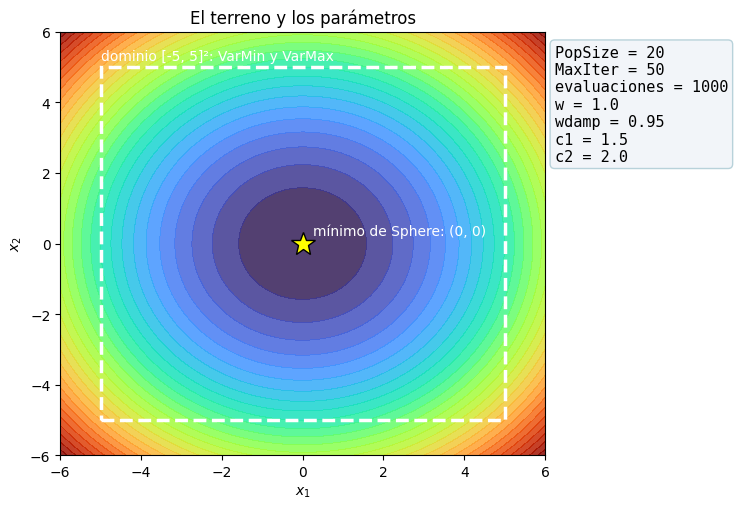

In [9]:
hidra.terreno_parametros(Sphere, VarMin, VarMax, {'PopSize': PopSize, 'MaxIter': MaxIter, 'evaluaciones': PopSize * MaxIter, 'w': w, 'wdamp': wdamp, 'c1': c1, 'c2': c2})

**Bloque 2: la población inicial.** Cada partícula nace en un lugar al azar del dominio, quieta (velocidad cero). Su mejor posición propia, de momento,
es donde nació. El mejor global es la mejor de todas.

In [10]:
# Template de la particula
empty_particle = {'position': None, 'velocity': None, 'cost': None, 'best_position': None, 'best_cost': None}

# Crear población inicial
pop = []
gbest = {'position': None, 'cost': np.inf}
for i in range(0, PopSize):
    pop.append(empty_particle.copy())
    pop[i]['position'] = np.random.uniform(VarMin, VarMax, nVar)
    pop[i]['velocity'] = np.zeros(nVar)
    pop[i]['cost'] = CostFunction(pop[i]['position'])
    pop[i]['best_position'] = pop[i]['position'].copy()
    pop[i]['best_cost'] = pop[i]['cost']
    if pop[i]['best_cost'] < gbest['cost']:
        gbest['position'] = pop[i]['best_position'].copy()
        gbest['cost'] = pop[i]['best_cost']

print(f"{PopSize} partículas creadas. Mejor costo inicial: {gbest['cost']:.4f} en {np.round(gbest['position'], 3)}")

20 partículas creadas. Mejor costo inicial: 1.0283 en [-0.827  0.587]


👀 **Cómo se ve la «librería» de partículas.** `pop` es una lista con un diccionario por partícula; cada diccionario guarda dónde está, cuánto se mueve, qué tan buena es y lo mejor que ha visto. A la izquierda, las mismas partículas sobre el terreno; a la derecha, la tabla con las primeras ocho. Todas nacen quietas (`velocity` = 0) y su mejor posición es donde nacieron.

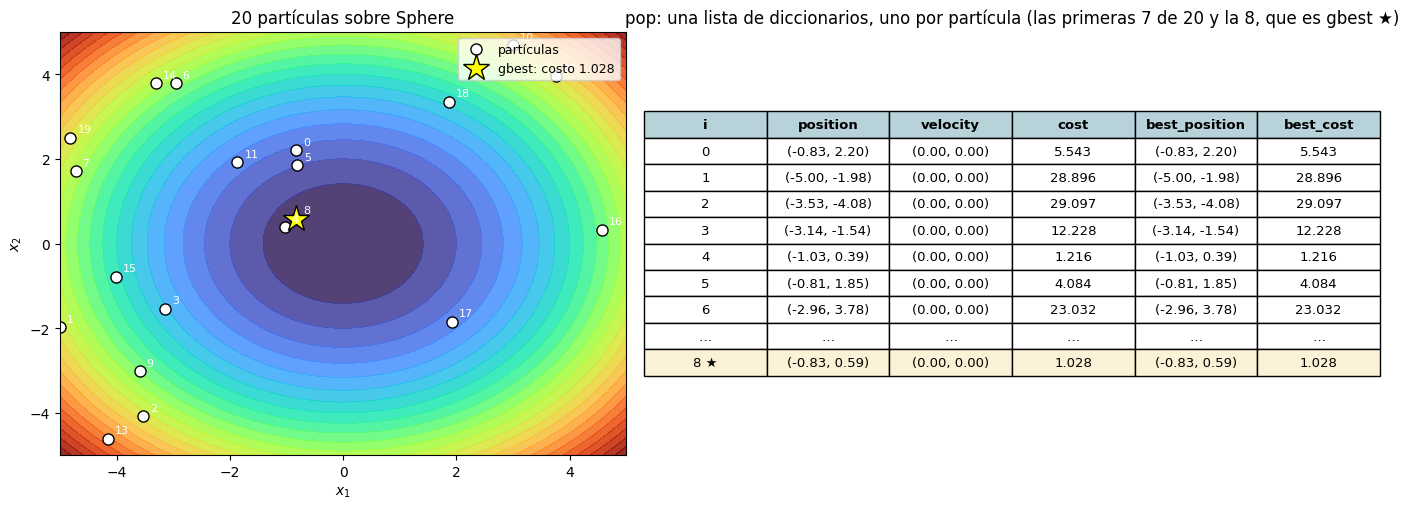

In [11]:
hidra.poblacion(pop, gbest, Sphere, VarMin, VarMax)

**Bloque 3: el ciclo principal.** Cada iteración mueve a todas las partículas con las dos ecuaciones, las evalúa y actualiza las memorias.

In [12]:
# PSO Loop principal
for it in range(0, MaxIter):
    for i in range(0, PopSize):

        pop[i]['velocity'] = w * pop[i]['velocity'] \
            + c1 * np.random.rand(nVar) * (pop[i]['best_position'] - pop[i]['position']) \
            + c2 * np.random.rand(nVar) * (gbest['position'] - pop[i]['position'])      # 1 inercia · 2 su experiencia · 3 la del enjambre

        pop[i]['position'] += pop[i]['velocity']                                       # la ecuación de posición
        pop[i]['position'] = np.clip(pop[i]['position'], VarMin, VarMax)               # acotamiento: no salir del dominio

        pop[i]['cost'] = CostFunction(pop[i]['position'])                              # evaluar: aquí iría la corrida del simulador

        if pop[i]['cost'] < pop[i]['best_cost']:                                       # ¿mejoró su propio récord?
            pop[i]['best_position'] = pop[i]['position'].copy()
            pop[i]['best_cost'] = pop[i]['cost']
            if pop[i]['best_cost'] < gbest['cost']:                                    # ¿mejoró el récord del enjambre?
                gbest['position'] = pop[i]['best_position'].copy()
                gbest['cost'] = pop[i]['best_cost']

    w *= wdamp                                                                         # la inercia se amortigua

print(f"Después de {MaxIter} iteraciones ({MaxIter * PopSize} evaluaciones): mejor costo = {gbest['cost']:.2e} en {np.round(gbest['position'], 5)}")

Después de 50 iteraciones (1000 evaluaciones): mejor costo = 2.00e-17 en [-0. -0.]


👀 **El ciclo, visto por fuera.** La misma corrida (misma semilla) guardando dónde estuvo cada partícula en cada iteración: cuatro instantes del enjambre y la curva de convergencia del mejor costo. Al principio exploran; al final se juntan en el fondo del valle.

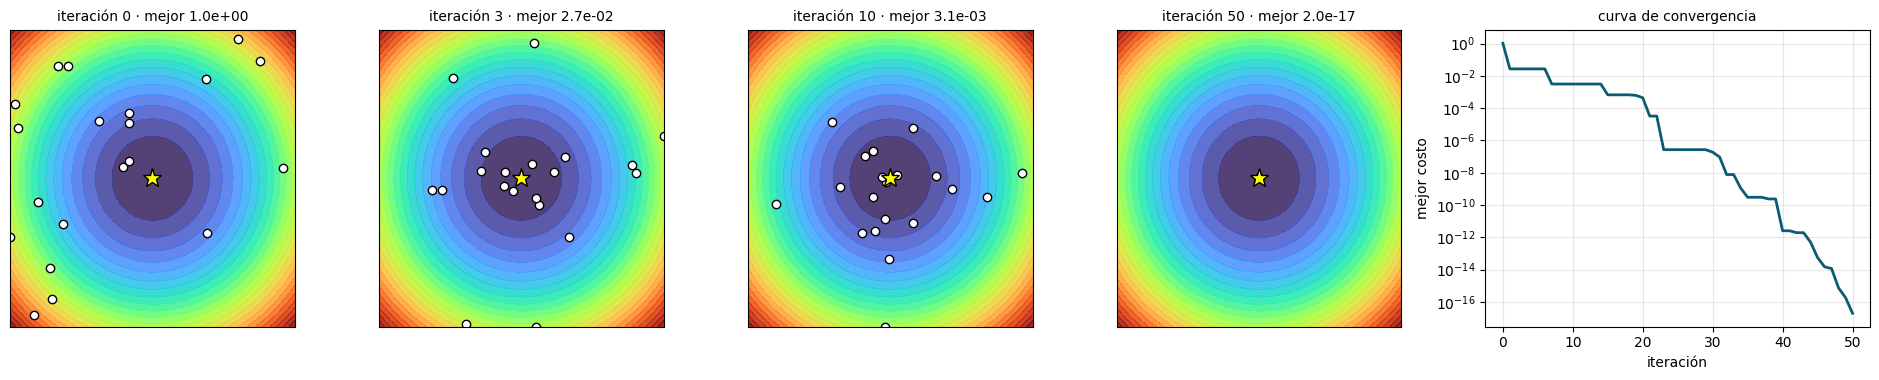

la historia guardada: H_pp tiene forma (51, 20, 2) = (iteraciones + 1, partículas, variables); el mejor costo final 2.00e-17, como arriba


In [13]:
def pso_guardando(semilla=1, w0=1.0):
    """Los bloques 2 y 3 otra vez, guardando la historia. Mismos parámetros del bloque 1 (w0 es la w inicial, que el bloque 3 fue amortiguando)."""
    np.random.seed(semilla); w_ = w0
    pos = np.array([np.random.uniform(VarMin, VarMax, nVar) for _ in range(PopSize)]); vel = np.zeros((PopSize, nVar))
    costo = np.array([CostFunction(x) for x in pos]); pb, pbc = pos.copy(), costo.copy(); k = int(np.argmin(pbc)); g, gc = pb[k].copy(), pbc[k]
    H, Hg = [pos.copy()], [gc]
    for it_ in range(MaxIter):
        for i_ in range(PopSize):
            vel[i_] = w_ * vel[i_] + c1 * np.random.rand(nVar) * (pb[i_] - pos[i_]) + c2 * np.random.rand(nVar) * (g - pos[i_])
            pos[i_] = np.clip(pos[i_] + vel[i_], VarMin, VarMax); costo[i_] = CostFunction(pos[i_])
            if costo[i_] < pbc[i_]:
                pb[i_], pbc[i_] = pos[i_].copy(), costo[i_]
                if costo[i_] < gc: g, gc = pos[i_].copy(), costo[i_]
        w_ *= wdamp; H.append(pos.copy()); Hg.append(gc)
    return np.array(H), np.array(Hg)

H_pp, Hg_pp = pso_guardando()

hidra.instantes(H_pp, Hg_pp, Sphere, VarMin, VarMax, iteraciones=(0, 3, 10, MaxIter))
print(f"la historia guardada: H_pp tiene forma {H_pp.shape} = (iteraciones + 1, partículas, variables); el mejor costo final {Hg_pp[-1]:.2e}, como arriba")

<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 2 · Apaga la cooperación, apaga la memoria</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: es la corrida del paso a paso (misma semilla, 20 × 50) pero con <code>c2 = 0</code>: nadie escucha al enjambre.</li><li>Pon <code>c1_tt, c2_tt = 0.0, 2.0</code> (nadie recuerda lo suyo) y vuelve a ejecutar.</li><li>Vuelve a <code>1.5, 2.0</code> para recuperar el resultado de arriba.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · el mejor costo final de cada corrida, frente al 2.00 × 10⁻¹⁷ del paso a paso.</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · ¿cuál de los dos términos es indispensable aquí? ¿Por qué con <code>c2 = 0</code> el enjambre ni siquiera se mueve?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con c₂ = 0 el costo se queda en 1.03, el de la población inicial: la velocidad arranca en cero y p = x, así que ningún término empuja y nadie se mueve. Con c₁ = 0 llega igual (≈10⁻¹⁸): en un valle sin trampas la memoria sobra. Con los dos, 2 × 10⁻¹⁷. Es el dilema cooperación contra competencia de las láminas: aquí gana la cooperación; en Ackley (ejemplo 3) la memoria vuelve a importar.</p></details>
</div>

In [14]:
c1_tt, c2_tt = 1.5, 0.0                  # ← prueba (1.5, 0.0), (0.0, 2.0) y (1.5, 2.0)
np.random.seed(1)
g_tt, _ = pso.PSO(problem, MaxIter=50, PopSize=20, c1=c1_tt, c2=c2_tt, w=1.0, wdamp=0.95, verbose=False)
print(f"c1 = {c1_tt}, c2 = {c2_tt}: mejor costo {g_tt['cost']:.2e} en {np.round(g_tt['position'], 4)}   (20 partículas × 50 iteraciones en Sphere)")

c1 = 1.5, c2 = 0.0: mejor costo 1.03e+00 en [-0.827   0.5869]   (20 partículas × 50 iteraciones en Sphere)


Eso es todo el PSO. `pso.py` hace exactamente lo mismo, con dos añadidos que usaremos en la sección 2: puede **maximizar** (`'MinProblem': 0`) y puede
**reparar** cada posición con una función (`'ResFunction'`).

### 1.6 Ejemplos de uso del algoritmo

Ejemplos cortos para aprender a **usar** PSO: qué devuelve, qué mover y qué esperar. En la sesión vemos los ejemplos 1, 2, 3 y 5; los ejemplos 4, 6 y 7 están en el **Apéndice · en casa**, al final del cuaderno.

#### Ejemplo 1 · ¿Qué devuelve PSO?

`pso.PSO` devuelve `gbest` (la mejor posición y su costo) y `pop` (todas las partículas al final). Además, `pso.historial` guarda el mejor costo de cada
iteración: con él se dibuja la **curva de convergencia**.

gbest tiene las llaves: ['position', 'cost'] | pop es una lista de 50 partículas con llaves ['position', 'velocity', 'cost', 'best_position', 'best_cost']


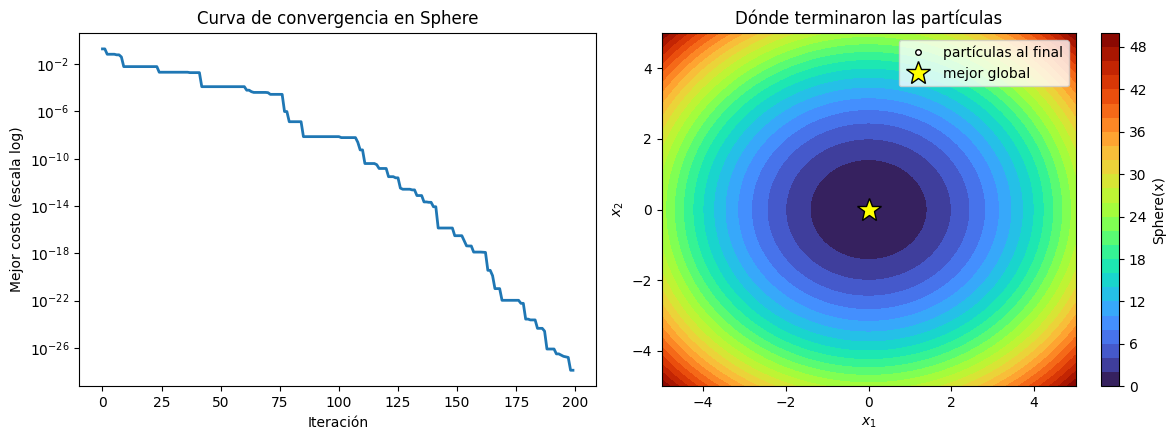

In [15]:
np.random.seed(0)
gbest, pop = pso.PSO(problem, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
print("gbest tiene las llaves:", list(gbest.keys()), "| pop es una lista de", len(pop), "partículas con llaves", list(pop[0].keys()))

hidra.resultado_enjambre(pso.historial, pop, gbest, Sphere, problem['VarMin'], problem['VarMax'])

👀 **Cómo se consulta cada cosa.** Tres celdas con lo que se escribe para leer el resultado: primero `gbest`, después una partícula cualquiera de `pop`, y por último `pso.historial`. Cambia los índices y vuelve a ejecutar.

In [16]:
# 1 · gbest: un diccionario con dos llaves
print("gbest completo:", gbest)
print("la mejor posición encontrada:", gbest['position'])
print("su costo:", gbest['cost'])
print("como número con formato: costo = {:.2e}, x1 = {:.4f}, x2 = {:.4f}".format(gbest['cost'], gbest['position'][0], gbest['position'][1]))

gbest completo: {'position': array([ 4.57387833e-15, -1.03155035e-14]), 'cost': np.float64(1.273299744429373e-28)}
la mejor posición encontrada: [ 4.57387833e-15 -1.03155035e-14]
su costo: 1.273299744429373e-28
como número con formato: costo = 1.27e-28, x1 = 0.0000, x2 = -0.0000


In [17]:
# 2 · pop: una lista de partículas; cada partícula es un diccionario con cinco llaves
print("pop tiene", len(pop), "partículas; la primera es:")
print(pop[0])
print()
p7 = pop[7]                                         # ← cambia el índice: de 0 a 49
fmt = lambda v: "(" + ", ".join(f"{x:.2e}" for x in v) + ")"      # al final de la corrida los números son diminutos: mejor en notación científica
print("partícula 7: está en", fmt(p7['position']), "| se mueve con velocidad", fmt(p7['velocity']), "| su costo ahora", f"{p7['cost']:.2e}")
print("            lo mejor que ha visto:", fmt(p7['best_position']), "con costo", f"{p7['best_cost']:.2e}")
costos_finales = np.array([p['cost'] for p in pop])
print(f"\ncostos finales de las 50: mínimo {costos_finales.min():.2e}, mediana {np.median(costos_finales):.2e}, máximo {costos_finales.max():.2e}")
print("¿cuál partícula es la mejor al final?", int(np.argmin([p['best_cost'] for p in pop])), "-> su best_cost coincide con gbest['cost']:", min(p['best_cost'] for p in pop) == gbest['cost'])

pop tiene 50 partículas; la primera es:
{'position': array([-1.13669345e-12,  3.22552444e-12]), 'velocity': array([ 2.69053862e-12, -7.42782775e-13]), 'cost': np.float64(1.1696079948991639e-23), 'best_position': array([-1.13669345e-12,  3.22552444e-12]), 'best_cost': np.float64(1.1696079948991639e-23)}

partícula 7: está en (-4.86e-10, -3.85e-10) | se mueve con velocidad (1.73e-09, -9.83e-10) | su costo ahora 3.84e-19
            lo mejor que ha visto: (-4.86e-10, -3.85e-10) con costo 3.84e-19

costos finales de las 50: mínimo 1.41e-28, mediana 8.35e-24, máximo 5.10e-17
¿cuál partícula es la mejor al final? 18 -> su best_cost coincide con gbest['cost']: True


In [18]:
# 3 · pso.historial: el mejor costo al final de cada iteración (una lista de MaxIter números)
print("iteraciones registradas:", len(pso.historial))
print("las primeras cinco:", [f"{h:.3g}" for h in pso.historial[:5]])
print("las últimas tres:  ", [f"{h:.3g}" for h in pso.historial[-3:]])
print("la mejor (la última, porque nunca empeora):", f"{pso.historial[-1]:.2e}", "= gbest['cost']:", pso.historial[-1] == gbest['cost'])
umbral = 1e-6
print(f"¿en qué iteración bajó de {umbral:g}? en la", int(np.argmax(np.array(pso.historial) < umbral)))

iteraciones registradas: 200
las primeras cinco: ['0.195', '0.195', '0.0687', '0.0687', '0.0687']
las últimas tres:   ['1.55e-27', '1.27e-28', '1.27e-28']
la mejor (la última, porque nunca empeora): 1.27e-28 = gbest['cost']: True
¿en qué iteración bajó de 1e-06? en la 77


#### Ejemplo 2 · El presupuesto: partículas por iteraciones

Cada evaluación cuesta. En el acuífero, cada evaluación será una corrida del simulador. ¿Cuánto presupuesto hace falta en Sphere de 5 variables?

In [19]:
problema_sphere5 = dict(problem, nVar=5)
print("partículas  iteraciones  evaluaciones   mejor costo")
for pop_size, max_iter in [(10, 20), (20, 50), (50, 100), (50, 200)]:
    np.random.seed(0)
    g, _ = pso.PSO(problema_sphere5, MaxIter=max_iter, PopSize=pop_size, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
    print(f"{pop_size:10d} {max_iter:12d} {pop_size * max_iter:13d}   {g['cost']:.2e}")

partículas  iteraciones  evaluaciones   mejor costo
        10           20           200   3.45e-01
        20           50          1000   4.21e-01
        50          100          5000   1.27e-04
        50          200         10000   3.13e-19


En general, más presupuesto da mejor resultado (con una sola semilla hay excepciones: lo vemos en el ejemplo 5), pero no es gratis. En un modelo regional de una hora por corrida, 10 000 evaluaciones son más de un año de cómputo:
el presupuesto manda.

#### Ejemplo 3 · Paisajes con trampas: Ackley

La función **Ackley** tiene su mínimo global también en el origen, pero rodeado de **cientos de mínimos locales**:

$$
f(\mathbf{x}) = -20\,\exp\!\left(-0.2\sqrt{\tfrac{1}{d}\textstyle\sum_{i} x_i^2}\right) - \exp\!\left(\tfrac{1}{d}\textstyle\sum_{i}\cos(2\pi x_i)\right) + 20 + e
$$

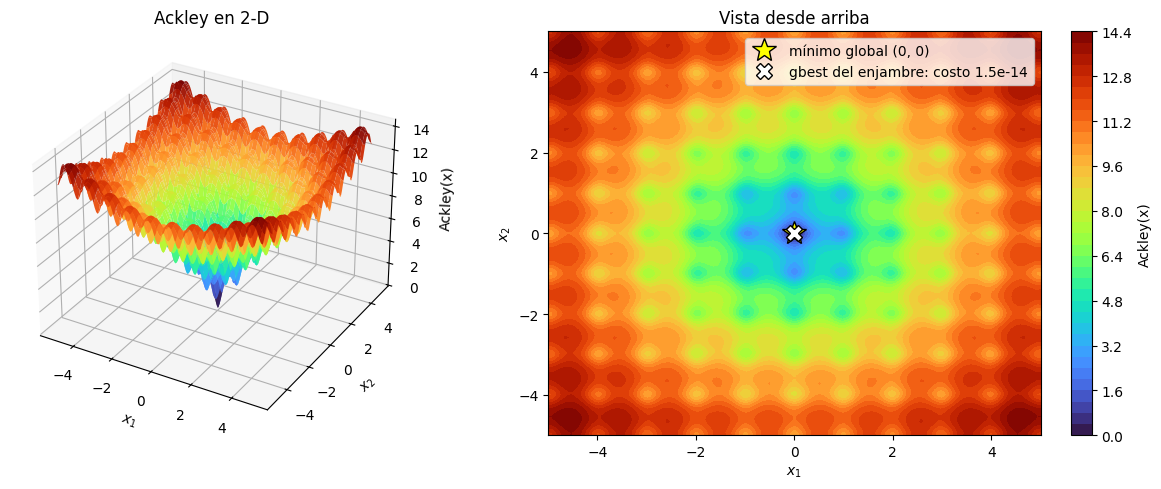

In [20]:
def Ackley(x):
    d = len(x)
    termino1 = -20 * np.exp(-0.2 * np.sqrt(np.sum(x**2) / d))     # el embudo grande
    termino2 = -np.exp(np.sum(np.cos(2 * np.pi * x)) / d)          # las ondulaciones: los mínimos locales
    return termino1 + termino2 + 20 + np.e


problema_ackley = {'CostFunction': Ackley, 'nVar': 2, 'VarMin': -5, 'VarMax': 5}
np.random.seed(0)
g_ack, _ = pso.PSO(problema_ackley, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)

hidra.superficie_prueba(Ackley, lim=(-5, 5), gbest=g_ack, nombre='Ackley')

En dos dimensiones el enjambre encuentra el origen. El problema aparece cuando crece la dimensión: con $d = 10$ variables y el dominio estándar,
$x_i \in [-32.768,\ 32.768]$, el espacio es astronómicamente mayor (la **maldición de la dimensionalidad**). El ejemplo 5 (y el 4, en el apéndice) usan ese caso.

#### Ejemplo 5 · Una corrida no es un resultado

PSO es **estocástico**: con otra semilla, otra respuesta. Un resultado de metaheurística se reporta como **estadística de varias corridas**.

media = 0.3468 | desviación = 0.5292 | mejor = 1.64e-04 | peor = 1.1552
corridas atrapadas en un mínimo local (costo > 0.1): 3 de 10


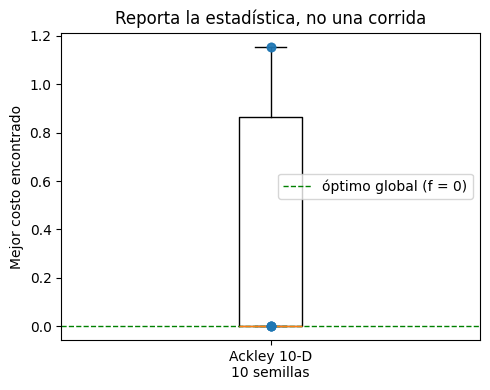

In [21]:
problema_ackley10 = {'CostFunction': Ackley, 'nVar': 10, 'VarMin': -32.768, 'VarMax': 32.768}
resultados = []
for semilla in range(10):
    np.random.seed(semilla)
    g, _ = pso.PSO(problema_ackley10, MaxIter=200, PopSize=20, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
    resultados.append(g['cost'])
resultados = np.array(resultados)
print(f"media = {resultados.mean():.4f} | desviación = {resultados.std():.4f} | mejor = {resultados.min():.2e} | peor = {resultados.max():.4f}")
print(f"corridas atrapadas en un mínimo local (costo > 0.1): {(resultados > 0.1).sum()} de 10")

hidra.estadistica_corridas(resultados, etiqueta='Ackley 10-D\n10 semillas')

La receta es siempre la misma: **(1)** una función que califica una decisión, **(2)** el diccionario `problem` (con `MinProblem` y `ResFunction` si
hacen falta), **(3)** los parámetros del enjambre, **(4)** `pso.PSO`. Es justo lo que haremos con el acuífero. (El ejemplo 6 del apéndice la aplica a una función propia, con `MinProblem` y `ResFunction`.)

<div style="border-left: 6px solid #C08A0B; background: #FBF1D6; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✔ Punto de control 1 · ⏸ Ejecuta hasta aquí</b> <span style="color:#54696F; font-size:0.8em;">· minuto 18 del cuaderno</span></p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Debes ver</b> · Debes ver: Sphere con costo del orden de 10⁻²⁸ en (0, 0), cero numérico; el paso a paso con 20 partículas llega a ~10⁻¹⁷; en Ackley 10-D con diez semillas, <b>3 de 10 corridas atrapadas</b> (costo &gt; 0.1).</p>
<p style="margin: 0; color:#54696F;">Si tu resultado no coincide, avisa en el chat antes de seguir; si coincide, espera: seguimos juntos.</p>
</div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 2 · EL PROBLEMA HIDROGEOLÓGICO, LINEAL · PROGRAMA 2.4</p>

## 2 · El problema de Fritz, lineal (20 min)

### 2.1 Descripción del problema

Un propietario, Fritz, controla tres pozos de extracción de agua subterránea en el acuífero del curso (el de las sesiones 1 a 4, que simula `hidra`).

- El acuífero es **confinado** y el flujo está en **estado estacionario**.
- El **pozo 3** tiene un contrato: debe extraer **300 m³/d** constantes.
- El abatimiento en cualquier pozo no debe exceder **3 m**.
- El abatimiento en el **humedal** no debe exceder **1.25 m** (en el cuaderno original, el agotamiento del arroyo no debía exceder 1 400 m³/d).

**Pregunta.** Fritz quiere saber la cantidad máxima que puede bombear de manera constante de los tres pozos sin causar abatimientos indeseables ni dañar el humedal.

Este problema tiene solo dos variables libres ($p_1$ y $p_2$). Para ilustrar también el efecto del bombeo conocido del pozo 3, lo incluimos en la función objetivo.

#### Definición de la función objetivo

$$
\max Z = \sum_{i=1}^{M^{p}=3} p_{i}
$$

Sujeta a las siguientes condiciones / restricciones:

$$
p_1, p_2 \geq 0, \qquad p_3 = 300, \qquad s_1, s_2, s_3 \leq 3\ \text{m}, \qquad s_h \le 1.25\ \text{m}
$$

**donde** $p_i$ es el bombeo del pozo $i$ (m³/d), $s_j = \sum_i \alpha_{ji}\,p_i$ el abatimiento en el pozo $j$ y $s_h = \sum_i \alpha_{h,i}\,p_i$ el abatimiento en el
humedal, con la matriz de respuesta $\alpha$ que el simulador fabrica (sesión 1).

| Cuaderno original | Aquí |
|---|---|
| matriz $\alpha$ de Peralta (tabla) | matriz $\alpha$ de Fritz, fabricada con el simulador (`hidra`) |
| arroyo: $\beta \cdot p \le 1\,400$ m³/d | humedal: $\alpha_h \cdot p \le 1.25$ m |
| pozo 3 fijo en 600 m³/d | pozo 3 fijo en 300 m³/d (el acuífero de Fritz es menos transmisivo) |

#### a · Definir la función objetivo

Es la función `Pumping` del original: simula, comprueba las restricciones y califica. Si alguna regla se rompe, la calificación **cambia de signo**
($-\sum p_i$): esa es la manera en que el original castiga.

In [22]:
alpha = hidra.matriz_respuesta()          # 3 x 3: metros de abatimiento en cada pozo por cada m³/d de cada pozo
alpha_h = hidra.coeficientes_humedal()    # lo mismo, en el humedal
S_MAX, S_HUM, P3 = hidra.S_MAX, hidra.S_MAX_HUMEDAL, hidra.P3_COMPROMETIDO     # 3 m, 1.25 m y 300 m³/d

# Función objetivo de muestra
def Pumping(x):

    # 1.- Simulación (con la matriz de respuesta)
    s_sim = alpha @ x          # abatimiento en los tres pozos
    s_hum = alpha_h @ x        # abatimiento en el humedal

    # 2.- Integrar restricciones: si se respetan, el bombeo total; si no, el bombeo total con signo negativo
    if (s_sim <= S_MAX).all() and s_hum <= S_HUM:
        cost = np.sum(x)
    else:
        cost = -np.sum(x)

    return cost

print(Pumping(np.array([300.0, 100.0, P3])), Pumping(np.array([500.0, 500.0, P3])))

700.0 -1300.0


#### b · Definir las restricciones del problema

La restricción $p_3 = 300$ no se castiga: se **repara**. Después de cada movimiento, PSO aplica esta función a la partícula.

In [23]:
# Integrar restricción a las variables de decisión
def Restriction(x):
    x[2] = P3
    return x

### 2.2 La verdad exacta

El problema es lineal: `linprog` lo resuelve con garantía (sesión 1). Lo calculamos para tener contra qué medir al enjambre.

In [24]:
A = np.vstack([alpha[:, :2], alpha_h[:2]]); b = np.append(S_MAX - alpha[:, 2] * P3, S_HUM - alpha_h[2] * P3)
exacto = linprog(c=[-1, -1], A_ub=A, b_ub=b, bounds=[(0, 1000)] * 2, method='highs')
Z_exacto = exacto.x.sum() + P3
print(f"Verdad exacta (sesión 1): p1 = {exacto.x[0]:.2f}, p2 = {exacto.x[1]:.2f}, p3 = {P3:.0f}  ->  Z* = {Z_exacto:.2f} m³/d")

Verdad exacta (sesión 1): p1 = 370.88, p2 = 136.46, p3 = 300  ->  Z* = 807.34 m³/d


### 2.3 Definir las condiciones del problema y correr PSO

Dos claves más que en Sphere: `'ResFunction'` (la reparación) y `'MinProblem': 0` (**maximizar**).

In [25]:
# Definir el problema de optimización
problem = {
        'CostFunction': Pumping,
        'nVar': 3,
        'VarMin': 0,
        'VarMax': 1000,
        'ResFunction': Restriction,
        'MinProblem': 0,       # 0 = maximizar
    }

# Correr PSO
np.random.seed(0)
pso.tic()
print('Running PSO ...')
gbest, pop = pso.PSO(problem, MaxIter = 200, PopSize = 50, c1 = 1.5, c2 = 2, w = 1, wdamp = 0.995, verbose = False)
pso.toc()
historial_fritz = list(pso.historial)

# Resultados
for i, bombeo in enumerate(gbest['position'], start=1):
    print(f"Bombeo en pozo {i}: {bombeo:.2f}")
print(f"Bombeo total: {gbest['cost']:.2f}   (exacto: {Z_exacto:.2f}; error relativo {abs(gbest['cost'] - Z_exacto) / Z_exacto * 100:.3f} %)")

Running PSO ...
Elapsed time: 0.10 s
Bombeo en pozo 1: 370.87
Bombeo en pozo 2: 136.47
Bombeo en pozo 3: 300.00
Bombeo total: 807.34   (exacto: 807.34; error relativo 0.000 %)


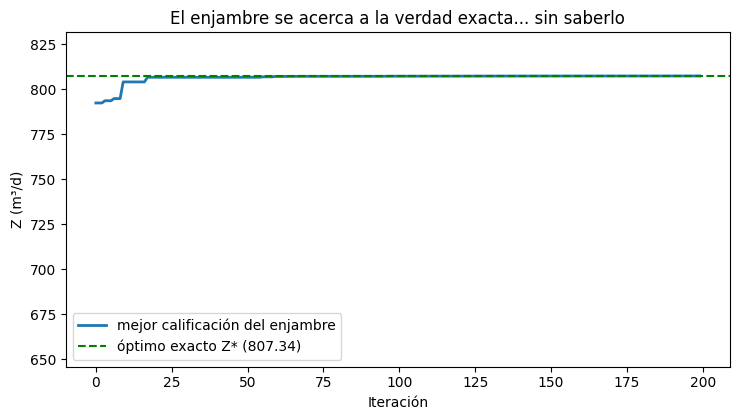

In [26]:
hidra.convergencia(historial_fritz, referencia=Z_exacto, etiqueta='mejor calificación del enjambre', etiqueta_ref='óptimo exacto Z*',
                   ylabel='Z (m³/d)', titulo='El enjambre se acerca a la verdad exacta... sin saberlo', ylim_rel=(0.8, 1.03))

<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 3 · Fritz renegocia el contrato del pozo 3</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: el pozo 3 pasa de 300 a <b>350 m³/d</b> (<code>P3_TT</code>).</li><li>Cambia <code>P3_TT</code> a 200 y vuelve a ejecutar; después a <b>400</b>.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · el total del enjambre frente al de linprog en la misma línea (arriba, con 300, eran 807.34 m³/d) y qué reglas quedan activas.</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · ¿sube o baja el total cuando el pozo 3 bombea más? ¿Por qué con 400 el enjambre se queda abajo del exacto?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con 350: 823.19 contra 823.29 de linprog, mismas reglas activas (pozo 1 y humedal). Con 200: 775.45, exacto. Con 400: 585.62 contra 595.33, un 1.6 % abajo. El pozo 3 se frena a sí mismo (su propia regla de 3 m se vuelve activa), la región factible se encoge y el castigo de signo deja al enjambre corto; linprog incluso apaga el pozo 1. Es lo que arregla la sección 2.4 con el castigo graduado.</p></details>
</div>

In [27]:
P3_TT = 350.0                            # ← el nuevo contrato del pozo 3 (prueba también 200 y 400)

def Pumping_tt(x):
    s_sim = alpha @ x; s_hum = alpha_h @ x
    return np.sum(x) if (s_sim <= S_MAX).all() and s_hum <= S_HUM else -np.sum(x)

def Restriction_tt(x):
    x[2] = P3_TT; return x

np.random.seed(0)
g_tt, _ = pso.PSO(dict(problem, CostFunction=Pumping_tt, ResFunction=Restriction_tt), MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
b_tt = np.append(S_MAX - alpha[:, 2] * P3_TT, S_HUM - alpha_h[2] * P3_TT)
ex_tt = linprog(c=[-1, -1], A_ub=A, b_ub=b_tt, bounds=[(0, 1000)] * 2, method='highs')
s_tt = alpha @ g_tt['position']; sh_tt = alpha_h @ g_tt['position']
print(f"pozo 3 en {P3_TT:.0f}: el enjambre da {g_tt['cost']:.2f} m³/d con p = {np.round(g_tt['position'], 2)} (linprog: {ex_tt.x.sum() + P3_TT:.2f}); antes, con 300, eran 807.34")
for nombre, s_, lim in zip(['pozo 1', 'pozo 2', 'pozo 3', 'humedal'], list(s_tt) + [sh_tt], [S_MAX] * 3 + [S_HUM]):
    print(f"   {nombre:8s} abatimiento {s_:.3f} m de {lim} m  {'ACTIVA' if abs(s_ - lim) < 0.01 else ''}")

pozo 3 en 350: el enjambre da 823.19 m³/d con p = [365.87 107.32 350.  ] (linprog: 823.29); antes, con 300, eran 807.34
   pozo 1   abatimiento 2.993 m de 3.0 m  ACTIVA
   pozo 2   abatimiento 1.513 m de 3.0 m  
   pozo 3   abatimiento 2.977 m de 3.0 m  
   humedal  abatimiento 1.250 m de 1.25 m  ACTIVA


**Lectura.** El enjambre llega casi a la misma respuesta que `linprog`. Pero `linprog` **demuestra** que no hay nada mejor (el certificado del vértice);
el enjambre solo puede decir «es lo mejor que vi». Hoy sabemos que acertó porque tenemos la verdad exacta. En la sección 3 no la tendremos.

### 2.4 Las restricciones y la escala del castigo

El castigo del original (cambiar el signo) es **discontinuo**: una decisión que rompe la regla por un milímetro vale lo mismo que una que la rompe por un
metro. La alternativa es un castigo **graduado**, proporcional al exceso:

$$
\text{calificación}(\mathbf{p}) = \sum_i p_i - M \left[\, \sum_j \max(0,\ s_j - 3) + \max(0,\ s_h - 1.25) \,\right]
$$

**donde** $M$ es el castigo en m³/d por cada metro de exceso. Si $M$ es pequeño, a la partícula le **conviene** romper la regla: el agua extra vale más que la multa.

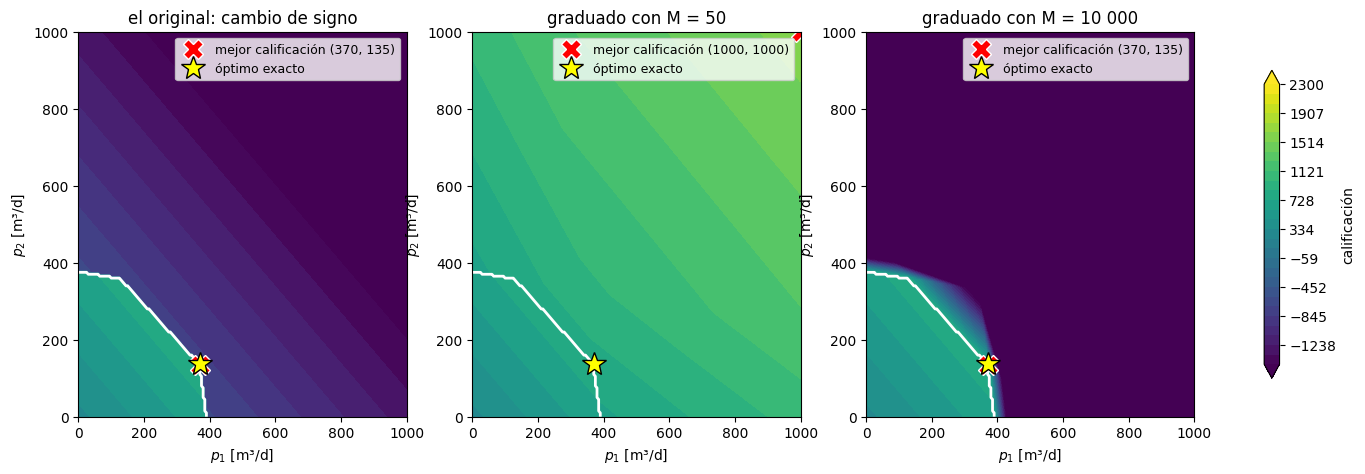

M =     50: p = [1000. 1000.  300.], abatimientos [8.17 8.44 4.3 ] m, humedal 3.90 m
M =  10000: p = [370.  137.3 300. ], abatimientos [2.99 1.68 2.66] m, humedal 1.25 m


In [28]:
def Pumping_graduado(x, M):
    exceso = np.sum(np.maximum(alpha @ x - S_MAX, 0)) + max(alpha_h @ x - S_HUM, 0)
    return np.sum(x) - M * exceso

hidra.paisajes_castigo(alpha, alpha_h, P3, S_MAX, S_HUM, exacto.x, Ms=(50, 10_000))

for M in (50, 10_000):
    np.random.seed(0)
    g, _ = pso.PSO(dict(problem, CostFunction=lambda x, M=M: Pumping_graduado(x, M)), MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
    print(f"M = {M:6d}: p = {np.round(g['position'], 1)}, abatimientos {np.round(alpha @ g['position'], 2)} m, humedal {alpha_h @ g['position']:.2f} m")

Con $M = 50$ la cima del paisaje está **fuera** de la región factible (la línea blanca) y el enjambre la encuentra: rompe las reglas. Con el cambio de signo
o con $M$ grande, la cima coincide con el vértice exacto. **El castigo debe estar en la escala de lo que se gana rompiendo la regla.**

<div style="border-left: 6px solid #C08A0B; background: #FBF1D6; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✔ Punto de control 2 · ⏸ Ejecuta hasta aquí</b> <span style="color:#54696F; font-size:0.8em;">· minuto 38 del cuaderno</span></p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Debes ver</b> · Debes ver: el enjambre en <b>807.34 m³/d</b> con p = (370.87, 136.47, 300), error 0.000 % contra linprog; con M = 50 el enjambre rompe las reglas (p₁ = p₂ = 1000) y con M = 10 000 vuelve al vértice.</p>
<p style="margin: 0; color:#54696F;">Si tu resultado no coincide, avisa en el chat antes de seguir; si coincide, espera: seguimos juntos.</p>
</div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 3 · LA AMPLIACIÓN NO LINEAL · PROGRAMA 2.4</p>

## 3 · El mismo problema, no lineal: el beneficio neto (15 min)

En la sección 2 el enjambre resolvió lo que `linprog` ya resolvía. Ahora el problema que justifica al enjambre: Fritz ya no quiere **el máximo de agua**,
quiere el **máximo beneficio**. Vende el agua, pero bombearla le cuesta, y el costo crece con el abatimiento.

### 3.1 Definición de la función objetivo

$$
\max\; B(\mathbf{p}) \;=\; P \sum_{i=1}^{3} p_i \;-\; \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big)
$$

**donde**:

- $P = 0.11$ \$ por m³ es el **precio** al que Fritz vende el agua.
- El segundo término es el **costo del bombeo**, la función objetivo 2 del cuaderno original de la sesión 3: $c_i$ es el coeficiente de costo
  ($0.01,\ 0.015,\ 0.02$), $\text{H}_i$ la cota del terreno (40 m), $h_i^0$ el nivel estático ($34,\ 34,\ 15$ m) y $s_i$ el abatimiento. La **altura de
  bombeo** $\text{H}_i - h_i^0 + s_i$ crece con el bombeo, así que el costo crece **con el cuadrado** del bombeo.
- Ahora los **tres pozos** se deciden (de 0 a 500 m³/d): el contrato del pozo 3 se renegoció.

**Restricciones:** las mismas, $s_j \le 3$ m en los pozos y $s_h \le 1.25$ m en el humedal.

Como $s_i$ depende de los bombeos, $B$ es **no lineal**: ya no hay vértice que buscar, y `linprog` no puede resolverlo.

In [29]:
PRECIO = 0.11                                   # $ por m³
C_QP = np.array([0.01, 0.015, 0.02])            # coeficiente de costo de cada pozo
GSLEV = np.array([40.0, 40.0, 40.0])            # cota del terreno [m]
H0 = np.array([34.0, 34.0, 15.0])               # nivel estático [m]: los pozos 1 y 2 junto al humedal, someros; el 3, hondo

def beneficio(x, precio=PRECIO):
    s = alpha @ x
    return precio * np.sum(x) - np.sum(C_QP * x * (GSLEV - H0 + s))

for p in [(200, 100, 0), (400, 100, 0), (300, 300, 100)]:
    x = np.array(p, float)
    print(f"bombeos {p}: beneficio {beneficio(x):6.2f} $/d | pozos {np.round(alpha @ x, 2)} m | humedal {alpha_h @ x:.2f} m")

bombeos (200, 100, 0): beneficio   7.71 $/d | pozos [1.46 0.92 0.34] m | humedal 0.52 m
bombeos (400, 100, 0): beneficio   9.05 $/d | pozos [2.81 1.13 0.56] m | humedal 0.86 m
bombeos (300, 300, 100): beneficio -39.54 $/d | pozos [2.46 2.54 1.36] m | humedal 1.18 m


👀 **El beneficio, en un dibujo.** Solo el pozo 1 bombeando, de 0 a 500 m³/d: el ingreso crece en línea recta con el bombeo, pero el costo crece cada vez más rápido porque el abatimiento sube la altura de bombeo. La diferencia, el beneficio, tiene un máximo en el interior: ahí ya no frena una regla, frena la economía.

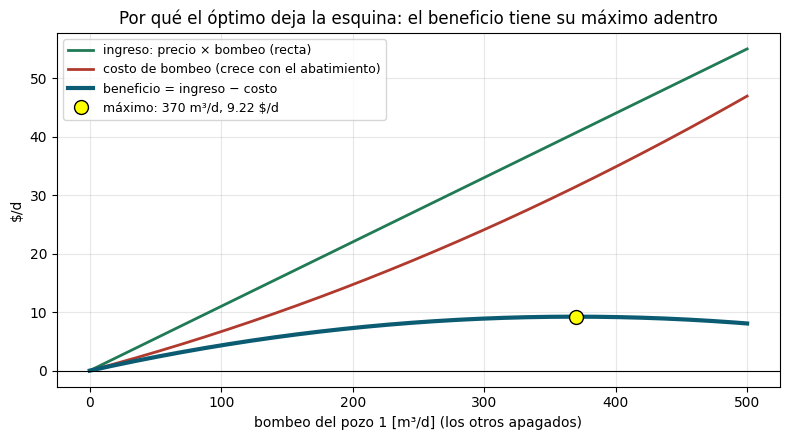

In [30]:
hidra.curva_beneficio(PRECIO, alpha, C_QP, GSLEV, H0, pozo=0)

### 3.2 La referencia: una malla de decisiones

Sin `linprog`, ¿contra qué medimos al enjambre? Igual que en la sesión 3: evaluamos una **malla** de decisiones (cada 5 m³/d), nos quedamos con las legales
y tomamos la mejor. No es exacta, pero es una referencia fina.

405684 decisiones legales; la mejor: p = [360.  50.   0.] m³/d, beneficio 9.48 $/d
abatimientos en los pozos: [2.49 0.73 0.47] m | humedal: 0.7 m  -> ninguna regla está en su límite


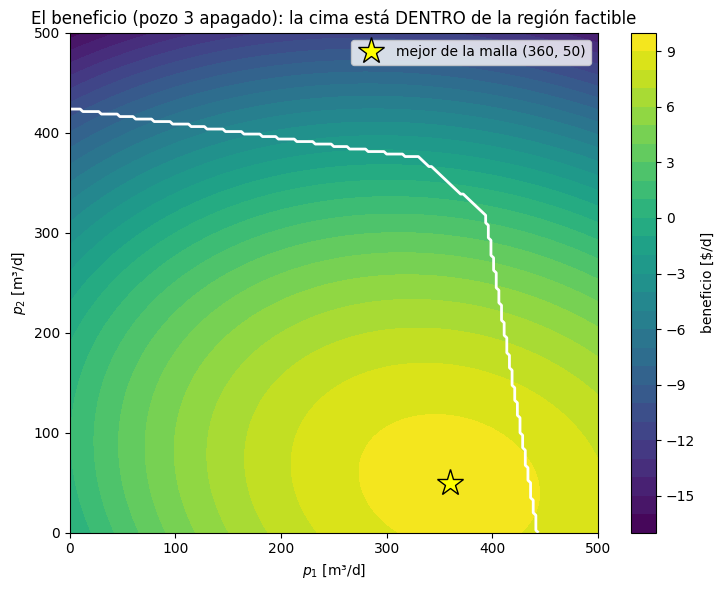

In [31]:
g = np.arange(0, 501, 5.0)
X_malla = np.array(np.meshgrid(g, g, g, indexing='ij')).reshape(3, -1).T          # 1 030 301 decisiones
S_malla = X_malla @ alpha.T
legal = (S_malla <= S_MAX).all(axis=1) & (X_malla @ alpha_h <= S_HUM)
X_leg, S_leg = X_malla[legal], S_malla[legal]

def beneficio_malla(precio):
    return precio * X_leg.sum(1) - (C_QP * X_leg * (GSLEV - H0 + S_leg)).sum(1)

B_leg = beneficio_malla(PRECIO)
k_ref = int(np.argmax(B_leg)); x_ref, B_ref = X_leg[k_ref], B_leg[k_ref]
print(f"{legal.sum()} decisiones legales; la mejor: p = {x_ref} m³/d, beneficio {B_ref:.2f} $/d")
print("abatimientos en los pozos:", np.round(alpha @ x_ref, 2), "m | humedal:", round(alpha_h @ x_ref, 2), "m  -> ninguna regla está en su límite")

hidra.paisaje_beneficio(alpha, alpha_h, PRECIO, C_QP, GSLEV, H0, S_MAX, S_HUM, x_ref)

**La diferencia esencial con la sección 2:** el óptimo ya no está en una esquina. Ninguna regla está en su límite: lo que frena a Fritz no es la física,
es la **economía**. Bombear un m³/d más cuesta más de lo que vale, porque cada m³ adicional abate más y sube la altura de bombeo de todos. Y el pozo 3
no bombea: está hondo y su agua no paga su costo.

### 3.3 PSO contra la referencia

Elapsed time: 0.14 s
PSO:   p = [359.3  49.9   0. ] m³/d, beneficio 9.483 $/d
malla: p = [360.  50.   0.] m³/d, beneficio 9.483 $/d
el enjambre queda arriba de la referencia por 0.000 $/d (la malla va de 5 en 5 m³/d)


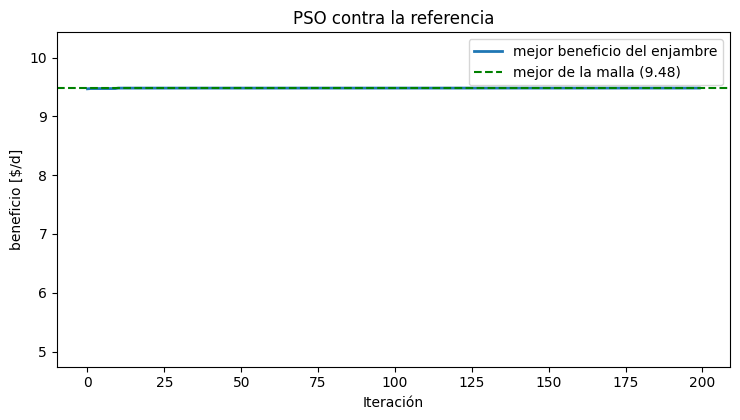

In [32]:
def Beneficio(x, M=10.0):
    exceso = np.sum(np.maximum(alpha @ x - S_MAX, 0)) + max(alpha_h @ x - S_HUM, 0)
    return beneficio(x) - M * exceso                          # castigo graduado, en la escala del beneficio ($)

problema_B = {'CostFunction': Beneficio, 'nVar': 3, 'VarMin': 0, 'VarMax': 500, 'MinProblem': 0}
np.random.seed(0)
pso.tic()
gbest_B, _ = pso.PSO(problema_B, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
pso.toc()
historial_B = list(pso.historial)
print(f"PSO:   p = {np.round(gbest_B['position'], 1)} m³/d, beneficio {gbest_B['cost']:.3f} $/d")
print(f"malla: p = {x_ref} m³/d, beneficio {B_ref:.3f} $/d")
print(f"el enjambre queda {'arriba' if gbest_B['cost'] >= B_ref else 'abajo'} de la referencia por {abs(gbest_B['cost'] - B_ref):.3f} $/d (la malla va de 5 en 5 m³/d)")

hidra.convergencia(historial_B, referencia=B_ref, etiqueta='mejor beneficio del enjambre', etiqueta_ref='mejor de la malla',
                   ylabel='beneficio [$/d]', titulo='PSO contra la referencia', ylim_rel=(0.5, 1.1))

El enjambre llega a la cima, e incluso puede quedar un poco **arriba** de la malla: la malla solo prueba múltiplos de 5 m³/d y el enjambre se mueve en continuo.

### 3.5 El enjambre llama directamente al simulador

Hasta aquí usamos la matriz porque el acuífero es lineal en las cargas. Pero el enjambre **no la necesita**: basta con que la calificación llame a
`hidra.simular`. Cada evaluación es ahora una solución completa de elementos finitos, así que usamos un presupuesto chico: 15 partículas × 30 iteraciones
= 450 corridas del simulador.

Elapsed time: 2.27 s
enjambre con el simulador: p = [359.3  49.9   0. ], beneficio 9.483 $/d (referencia 9.483), con solo 450 corridas


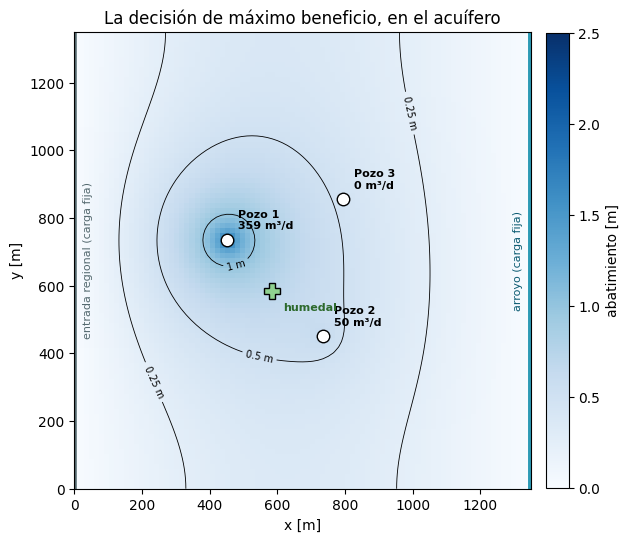

In [33]:
# Esta celda tarda unos segundos
def Beneficio_simulador(x, M=10.0):
    r = hidra.simular(x)                                                          # 1 · una corrida completa del simulador
    costo = np.sum(C_QP * x * (GSLEV - H0 + r.abatimiento_pozos))                 # 2 · el costo con los abatimientos simulados
    exceso = np.sum(np.maximum(r.abatimiento_pozos - S_MAX, 0)) + max(r.abatimiento_humedal - S_HUM, 0)
    return PRECIO * np.sum(x) - costo - M * exceso                                # 3 · igual que antes

np.random.seed(0)
pso.tic()
gbest_s, _ = pso.PSO(dict(problema_B, CostFunction=Beneficio_simulador), MaxIter=30, PopSize=15, c1=1.5, c2=2, w=1, wdamp=0.95, verbose=False)
pso.toc()
print(f"enjambre con el simulador: p = {np.round(gbest_s['position'], 1)}, beneficio {gbest_s['cost']:.3f} $/d (referencia {B_ref:.3f}), con solo 450 corridas")
hidra.mapa(hidra.simular(gbest_s['position']), titulo='La decisión de máximo beneficio, en el acuífero'); plt.show()

Esta es la idea central de la simulación-optimización: **el optimizador propone, el simulador califica**. El precio es el número de corridas. Si mañana
el acuífero fuera libre o transitorio, este código seguiría funcionando; el de `linprog`, no.

<div style="border-left: 6px solid #2E9BB5; background: #E2EFF2; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✏️ Tu turno 4 · El agua sube de precio</b> <span style="color:#54696F; font-size:0.8em;">· 2 min · la celda de abajo es tuya</span></p>
<p style="margin: 0;"><b style="color:#0B5B72;">Qué hacer</b></p>
<ol style="margin: 2px 0 8px 0; padding-left: 1.4em;"><li>Ejecuta la celda tal como está: el agua pasa de 0.11 a <b>0.16 $/m³</b> (<code>PRECIO_TT</code>).</li><li>Cambia <code>PRECIO_TT</code> a 0.08 y vuelve a ejecutar; después a <b>0.20</b>.</li></ol>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Qué observar</b> · cuánto bombea cada pozo, el beneficio, y qué regla aparece como ACTIVA en la tabla (con 0.11 ninguna lo estaba).</p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Pregunta</b> · ¿qué regla choca primero cuando el agua vale más? ¿Y por qué con 0.20 el humedal se pasa unos centímetros?</p>
<details style="margin-top: 4px;"><summary style="cursor: pointer; color:#C08A0B;"><b>Cuando termines: lo que debías ver</b></summary>
<p style="margin: 4px 0 0 0;">Con 0.16: p = (403.9, 251.7, 0), 37.57 $/d y el pozo 1 activo. Con 0.08: (147.6, 0, 0), 1.48 $/d: casi no conviene bombear. Con 0.20: (390.4, 339.1, 0), 65.63 $/d y el humedal en 1.283 m, 3 cm pasado de la regla: M = 10 $/d por metro es poca multa cuando el agua vale tanto. Es el barrido de precios del apéndice, punto por punto.</p></details>
</div>

In [34]:
PRECIO_TT = 0.16                         # ← cambia el precio ($ por m³)

def Beneficio_tt(x, M=10.0):
    exceso = np.sum(np.maximum(alpha @ x - S_MAX, 0)) + max(alpha_h @ x - S_HUM, 0)
    return beneficio(x, precio=PRECIO_TT) - M * exceso

np.random.seed(0)
g_tt, _ = pso.PSO(dict(problema_B, CostFunction=Beneficio_tt), MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
s_tt = alpha @ g_tt['position']; sh_tt = alpha_h @ g_tt['position']
print(f"precio {PRECIO_TT:.2f} $/m³: p = {np.round(g_tt['position'], 1)} m³/d, beneficio {g_tt['cost']:.3f} $/d   (con 0.11 era p = {np.round(gbest_B['position'], 1)}, {gbest_B['cost']:.3f} $/d)")
for nombre, s_, lim in zip(['pozo 1', 'pozo 2', 'pozo 3', 'humedal'], list(s_tt) + [sh_tt], [S_MAX] * 3 + [S_HUM]):
    print(f"   {nombre:8s} abatimiento {s_:.3f} m de {lim} m  {'ACTIVA' if abs(s_ - lim) < 0.01 else ''}")

precio 0.16 $/m³: p = [403.9 251.7   0. ] m³/d, beneficio 37.573 $/d   (con 0.11 era p = [359.3  49.9   0. ], 9.483 $/d)
   pozo 1   abatimiento 3.000 m de 3.0 m  ACTIVA
   pozo 2   abatimiento 2.203 m de 3.0 m  
   pozo 3   abatimiento 0.730 m de 3.0 m  
   humedal  abatimiento 1.146 m de 1.25 m  


<div style="border-left: 6px solid #C08A0B; background: #FBF1D6; color: #1B2B33; padding: 12px 16px; margin: 18px 0; line-height: 1.45;">
<p style="margin: 0 0 6px 0; font-size: 1.15em;"><b>✔ Punto de control 3 · ⏸ Ejecuta hasta aquí</b> <span style="color:#54696F; font-size:0.8em;">· minuto 53 del cuaderno</span></p>
<p style="margin: 0 0 6px 0;"><b style="color:#0B5B72;">Debes ver</b> · Debes ver: el beneficio máximo <b>9.483 $/d</b> con p ≈ (359, 50, 0), igual que la malla; ninguna regla activa; y el enjambre con <code>hidra.simular</code> llega al mismo punto con 450 corridas.</p>
<p style="margin: 0; color:#54696F;">Si tu resultado no coincide, avisa en el chat antes de seguir; si coincide, espera: seguimos juntos.</p>
</div>

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 4 · OTRA GEOLOGÍA, OTRO ÓPTIMO · EL PUENTE A LA SESIÓN 4</p>

## 4 · Otra geología, otro óptimo (7 min)

Todo lo anterior supone el acuífero **homogéneo**. `hidra` trae diez geologías heterogéneas posibles, todas compatibles con lo que sabemos del acuífero.
Con cada una la matriz cambia, y con ella los dos óptimos de hoy: el lineal (sección 2) y el de máximo beneficio (sección 3).

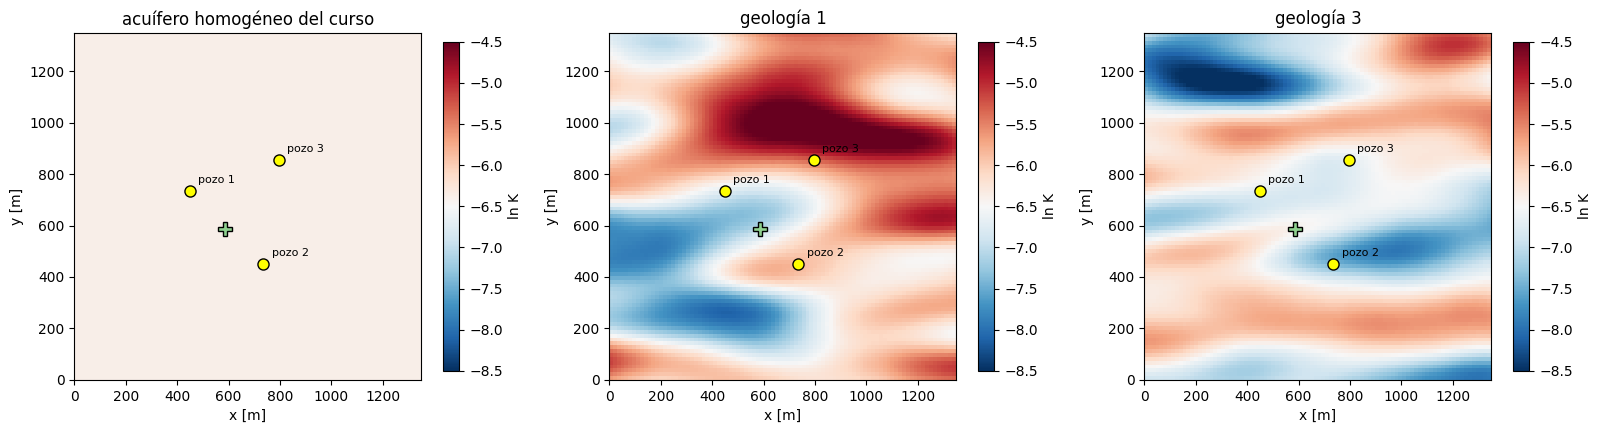

geología        óptimo lineal Z* [m³/d]   máximo beneficio [$/d] con p [m³/d]


homogéneo                       807.3         9.48  con [360.  50.   0.]


geología 1                     1005.2         8.71  con [310. 100.   0.]


geología 3                      738.7         7.50  con [290.  30.   0.]


In [35]:
hidra.mapas_geologias((None, 1, 3))

print("geología        óptimo lineal Z* [m³/d]   máximo beneficio [$/d] con p [m³/d]")
for geo in [None, 1, 3]:
    al_g, ah_g = hidra.matriz_respuesta(geo), hidra.coeficientes_humedal(geo)
    r = linprog([-1, -1], A_ub=np.vstack([al_g[:, :2], ah_g[:2]]), b_ub=np.append(S_MAX - al_g[:, 2] * P3, S_HUM - ah_g[2] * P3),
                bounds=[(0, 1000)] * 2, method='highs')
    z_lin = f"{r.x.sum() + P3:8.1f}" if r.status == 0 else "  sin solución"
    Sg = X_malla @ al_g.T; okg = (Sg <= S_MAX).all(axis=1) & (X_malla @ ah_g <= S_HUM)
    Bg = PRECIO * X_malla[okg].sum(1) - (C_QP * X_malla[okg] * (GSLEV - H0 + Sg[okg])).sum(1)
    kg = np.argmax(Bg)
    print(f"{'homogéneo' if geo is None else 'geología ' + str(geo):14s} {z_lin:>22s}   {Bg[kg]:10.2f}  con {X_malla[okg][kg]}")

La respuesta que le damos a Fritz depende de una geología que **no conocemos**: con otra, los pozos abaten distinto, el costo cambia y el óptimo se mueve.
La sesión 4 toma muchas geologías a la vez: ¿qué decisión resiste a todas?

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">SECCIÓN 5 · CIERRE Y TAREA</p>

## 5 · Cierre: lo que el enjambre sí y no hace (5 min)

| | Programación lineal (sesión 1) | Enjambre de partículas (hoy) |
|---|---|---|
| Qué necesita | la matriz y todo lineal | solo poder calificar una decisión |
| Problema lineal (sección 2) | exacto, con certificado | casi igual, sin certificado |
| Problema no lineal (sección 3) | no aplica | lo resuelve; se valida contra una referencia |
| Restricciones | aparte, exactas | dentro de la calificación: el castigo debe estar en la escala correcta |
| Lo que hay que reportar | el óptimo | el óptimo de varias corridas, con su estadística |

**El martes que viene:** Fritz ya no quiere solo un número. El costo de hoy, el agua y la necesidad de cubrirla **se pelean entre sí**: varios objetivos a la
vez, con OMOPSO y el frente de Pareto.

### Tarea 2 (asíncrono, unas 2 horas)

`Tarea_2_estudiante.ipynb`, la misma para todos y con los datos de hoy: dos etapas sobre el algoritmo (un paso de la partícula a mano; apagar un término y cuándo parar) y luego la ruta de este cuaderno, desde tu propia función con PSO hasta las restricciones y su
castigo, el enjambre contra la verdad exacta, las semillas, el beneficio neto contra la referencia, el precio que mueve al óptimo y otra geología. Es el trabajo
asíncrono de la sesión y se califica: ofrece 12 puntos y la calificación se cierra en 10, tú eliges qué contestar; se aprueba con 6 de 10; con 2 de los 4 cuadernos de tarea aprobados, el examen del curso está aprobado. Entrega antes del 17 de noviembre.

### Referencias

- Kennedy, J. y Eberhart, R. (1995). Particle swarm optimization. *Proceedings of ICNN'95*, 4, 1942–1948.
- Clerc, M. y Kennedy, J. (2002). The particle swarm: explosion, stability, and convergence in a multidimensional complex space. *IEEE Transactions on Evolutionary Computation*, 6(1), 58–73.
- Clerc, M. (2010). *Particle Swarm Optimization*. John Wiley & Sons.
- Peralta, R. C. (2012). *Groundwater Optimization Handbook*. CRC Press. (El problema de los tres pozos.)
- Surjanovic, S. y Bingham, D. *Virtual Library of Simulation Experiments: Test Functions*. https://www.sfu.ca/~ssurjano/ (Sphere y Ackley.)

<hr style="border: none; border-top: 4px solid #0B5B72; margin: 28px 0 4px 0;">
<p style="color:#0B5B72; font-size: 0.85em; letter-spacing: 0.08em; margin: 0;">APÉNDICE · EN CASA · LO QUE NO CABE EN LA SESIÓN</p>

## Apéndice · En casa

Estas celdas salieron de la sesión para que el cuaderno quepa en el tiempo. Usan variables de las secciones de arriba (`Ackley`, `problem`, `alpha`,
`exacto`, `beneficio`…), así que **ejecuta el cuaderno completo en orden** antes de correrlas. Son cinco bloques: tres ejemplos de uso de PSO, la animación
del enjambre de Fritz sobre la región factible y el barrido de precios. La Tarea 2 usa ideas de los cinco.

#### Ejemplo 4 · Convergencia: el impacto de los parámetros

El mismo enjambre sobre Ackley de 10 variables, con **tres ajustes de la inercia** y la misma semilla:

| Ajuste | `w` | `wdamp` | Qué esperamos (lámina *Convergencia: el impacto de los parámetros*) |
|---|---|---|---|
| A · el del curso | 1.0 | 0.995 | explora al principio y explota al final |
| B · inercia baja fija | 0.4 | 1.0 | explota desde el inicio: rápido, pero puede atorarse |
| C · inercia alta sin amortiguar | 1.1 | 1.0 | fuera del rango estable: el enjambre no se calma |

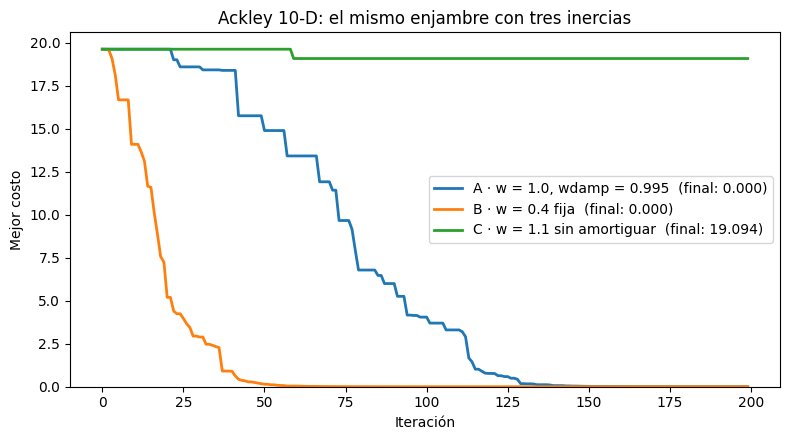

In [36]:
problema_ackley10 = {'CostFunction': Ackley, 'nVar': 10, 'VarMin': -32.768, 'VarMax': 32.768}
ajustes = {'A · w = 1.0, wdamp = 0.995': (1.0, 0.995), 'B · w = 0.4 fija': (0.4, 1.0), 'C · w = 1.1 sin amortiguar': (1.1, 1.0)}

historiales = {}
for nombre, (w_, wdamp_) in ajustes.items():
    np.random.seed(2)
    g, _ = pso.PSO(problema_ackley10, MaxIter=200, PopSize=30, c1=1.5, c2=2, w=w_, wdamp=wdamp_, verbose=False)
    historiales[f'{nombre}  (final: {g["cost"]:.3f})'] = list(pso.historial)
hidra.convergencias(historiales, titulo='Ackley 10-D: el mismo enjambre con tres inercias')

Una curva que baja rápido y se queda plana lejos de cero **convergió prematuramente**; una curva plana desde el principio **no converge**. Con esta semilla
la inercia baja (B) gana en rapidez; con las semillas 0 a 9, A queda atrapada 1 vez de 10, B 2 veces y C las 10. Rápido no es lo mismo que confiable.

✏️ **Inténtalo:** agrega un ajuste D con `c1 = c2 = 1.49445` y `w = 0.729` fija: los valores de constricción de Clerc y Kennedy (2002).

#### Ejemplo 6 · Tu propia función: maximizar y reparar

Para resolver **tu** problema basta escribir una función que reciba el vector de decisión y devuelva **un número**. Dos claves del diccionario cambian
el comportamiento: `'MinProblem': 0` para **maximizar**, y `'ResFunction'` para **reparar** cada posición después de moverla (por ejemplo, fijar una variable).

Ejemplo: maximizar $f(x_1, x_2) = 10 - (x_1 - 1)^2 - (x_2 + 2)^2$, cuyo máximo es 10 en $(1, -2)$, pero con $x_2$ fijo en 0 (entonces el máximo es 6, en $(1, 0)$).

In [37]:
def colina(x):
    return 10 - (x[0] - 1)**2 - (x[1] + 2)**2

def fija_x2(x):
    x[1] = 0.0                # reparación: x2 siempre vale 0
    return x

for nombre, prob in [('libre', {'CostFunction': colina, 'nVar': 2, 'VarMin': -5, 'VarMax': 5, 'MinProblem': 0}),
                     ('con x2 = 0', {'CostFunction': colina, 'nVar': 2, 'VarMin': -5, 'VarMax': 5, 'MinProblem': 0, 'ResFunction': fija_x2})]:
    np.random.seed(0)
    g, _ = pso.PSO(prob, MaxIter=100, PopSize=30, c1=1.5, c2=2, w=1, wdamp=0.99, verbose=False)
    print(f"{nombre:11s}: máximo {g['cost']:.4f} en {np.round(g['position'], 4)}")

libre      : máximo 10.0000 en [ 1. -2.]
con x2 = 0 : máximo 6.0000 en [1. 0.]


#### Ejemplo 7 · La animación: el enjambre en movimiento

El bloque 3 del paso a paso, guardando las posiciones de cada iteración sobre las curvas de nivel de Ackley. Se guarda en `Información/figuras/enjambre_ackley.gif`.

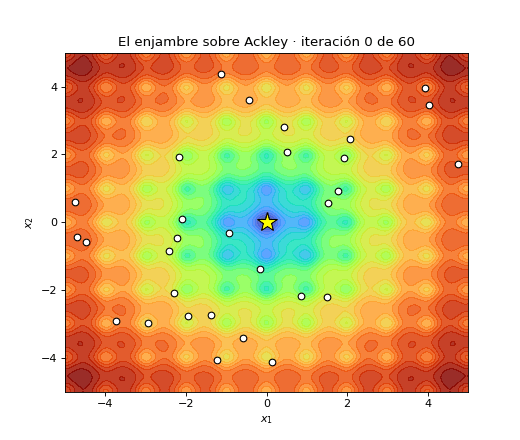

In [38]:
np.random.seed(3)
PopSize, MaxIter = 30, 60
w, wdamp, c1, c2 = 1.0, 0.95, 1.5, 2.0
posicion = np.random.uniform(-5, 5, (PopSize, 2)); velocidad = np.zeros((PopSize, 2))
mejor_pos_propia = posicion.copy(); mejor_costo_propio = np.array([Ackley(x) for x in posicion])
k = mejor_costo_propio.argmin(); g_pos, g_costo = mejor_pos_propia[k].copy(), mejor_costo_propio[k]
historia = [posicion.copy()]
for it in range(MaxIter):
    for i in range(PopSize):
        velocidad[i] = (w * velocidad[i] + c1 * np.random.rand(2) * (mejor_pos_propia[i] - posicion[i]) + c2 * np.random.rand(2) * (g_pos - posicion[i]))
        posicion[i] = np.clip(posicion[i] + velocidad[i], -5, 5)
        c = Ackley(posicion[i])
        if c < mejor_costo_propio[i]:
            mejor_pos_propia[i], mejor_costo_propio[i] = posicion[i].copy(), c
            if c < g_costo:
                g_pos, g_costo = posicion[i].copy(), c
    w *= wdamp
    historia.append(posicion.copy())

hidra.animar_enjambre(historia, 'Información/figuras/enjambre_ackley.gif', f=Ackley, lim=(-5, 5), titulo='El enjambre sobre Ackley')

### 2.5 La animación sobre la región factible

El enjambre visto en el plano $(p_1, p_2)$: el polígono es la región factible con el humedal, la estrella el óptimo exacto. Se guarda en `Información/figuras/enjambre_fritz.gif`.

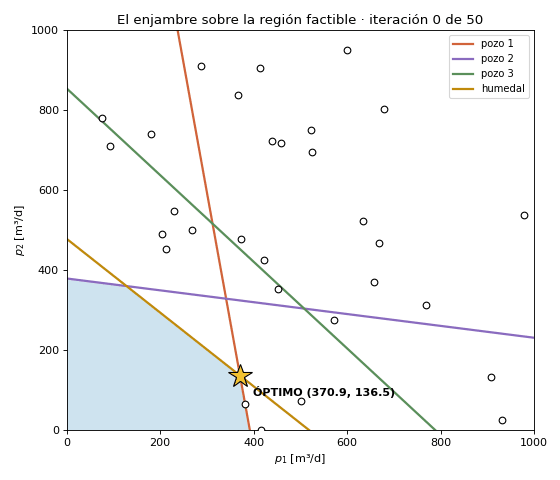

In [39]:
def calif_2d(q):
    return Pumping_graduado(np.array([q[0], q[1], P3]), 10_000)

np.random.seed(7)
PopSize, MaxIter = 30, 50
w, wdamp, c1, c2 = 1.0, 0.95, 1.5, 2.0
posicion = np.random.uniform(0, 1000, (PopSize, 2)); velocidad = np.zeros((PopSize, 2))
mejor_pos_propia = posicion.copy(); mejor_costo_propio = np.array([calif_2d(q) for q in posicion])
k = mejor_costo_propio.argmax(); g_pos, g_costo = mejor_pos_propia[k].copy(), mejor_costo_propio[k]
historia = [posicion.copy()]
for it in range(MaxIter):
    for i in range(PopSize):
        velocidad[i] = (w * velocidad[i] + c1 * np.random.rand(2) * (mejor_pos_propia[i] - posicion[i]) + c2 * np.random.rand(2) * (g_pos - posicion[i]))
        posicion[i] = np.clip(posicion[i] + velocidad[i], 0, 1000)
        c = calif_2d(posicion[i])
        if c > mejor_costo_propio[i]:                 # maximizar: ahora «mejor» es «mayor»
            mejor_pos_propia[i], mejor_costo_propio[i] = posicion[i].copy(), c
            if c > g_costo:
                g_pos, g_costo = posicion[i].copy(), c
    w *= wdamp
    historia.append(posicion.copy())

hidra.animar_enjambre(historia, 'Información/figuras/enjambre_fritz.gif', titulo='El enjambre sobre la región factible', fps=7,
                      region=dict(A=A, b=b, nombres=['pozo 1', 'pozo 2', 'pozo 3', 'humedal'], p_optimo=exacto.x))

### 3.4 El óptimo se mueve con el precio

¿Qué pasa si cambia el precio del agua? Comparamos con la versión **lineal** del mismo problema: el costo sin el abatimiento ($c_i\,p_i\,(\text{H}_i - h_i^0)$),
que `linprog` sí resuelve.

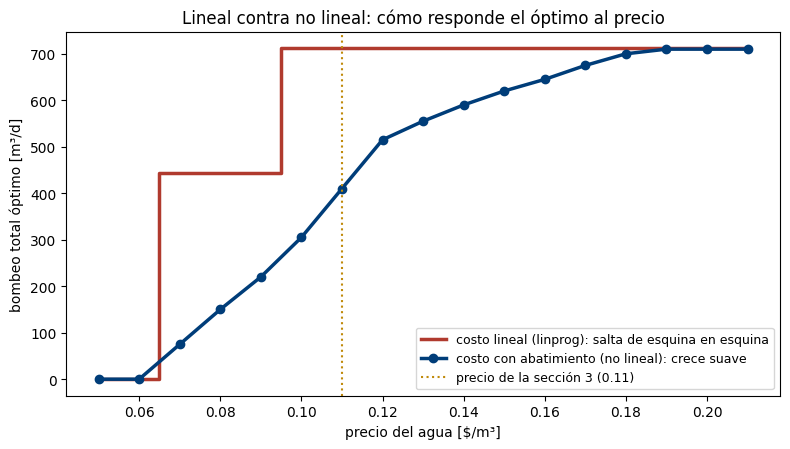

In [40]:
precios = np.round(np.arange(0.05, 0.22, 0.01), 2)
total_no_lineal, total_lineal = [], []
for pr in precios:
    Bp = beneficio_malla(pr); total_no_lineal.append(X_leg[np.argmax(Bp)].sum())
    r = linprog(-(pr - C_QP * (GSLEV - H0)), A_ub=np.vstack([alpha, alpha_h]), b_ub=[S_MAX] * 3 + [S_HUM], bounds=[(0, 500)] * 3, method='highs')
    total_lineal.append(r.x.sum())

hidra.optimo_contra_precio(precios, total_lineal, total_no_lineal, PRECIO)

En el problema **lineal** el óptimo solo puede estar en una esquina: con el precio bajo no conviene bombear, y en cuanto conviene, se bombea **todo** lo que
las reglas permiten. En el **no lineal** el óptimo crece poco a poco con el precio, hasta que choca con las reglas y se vuelve igual al lineal. Esa zona
intermedia, donde la economía manda, ya no la resuelve `linprog`. Aquí la física es lineal y el beneficio es cuadrático, así que un optimizador clásico con
gradiente también la resolvería; el enjambre se gana su lugar cuando la calificación es una **corrida del simulador** sin fórmula a la vista (sección 3.5).